# Hoja de trabajo 1 - KMeans

## Marco Alejandro Díaz Castañeda - 24229 
## 19/02/2026

## Variables del Dataset

- CustomerID: Identificador único del cliente
- Gender: 0 = Hombre, 1 = Mujer
- Age: Edad del cliente
- Annual Income (k$): Ingreso anual en miles de dólares
- Spending Score (1-100): Puntaje de gasto asignado por el mall

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
sns.set(style="whitegrid")


In [18]:
df=pd.read_csv("Mall_Customers_encoded.csv")

df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,0,19,15,39
1,2,0,21,15,81
2,3,1,20,16,6
3,4,1,23,16,77
4,5,1,31,17,40


In [19]:
df.info()

# Examen inicial sobre el data frame

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    int64
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(5)
memory usage: 7.9 KB


In [21]:
df.isnull().sum()


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [22]:
df.describe()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,0.560000,38.850000,60.560000,50.200000
std,57.879185,0.497633,13.969007,26.264721,25.823522
min,1.000000,0.000000,18.000000,15.000000,1.000000
25%,50.750000,0.000000,28.750000,41.500000,34.750000
50%,100.500000,1.000000,36.000000,61.500000,50.000000
75%,150.250000,1.000000,49.000000,78.000000,73.000000
max,200.000000,1.000000,70.000000,137.000000,99.000000


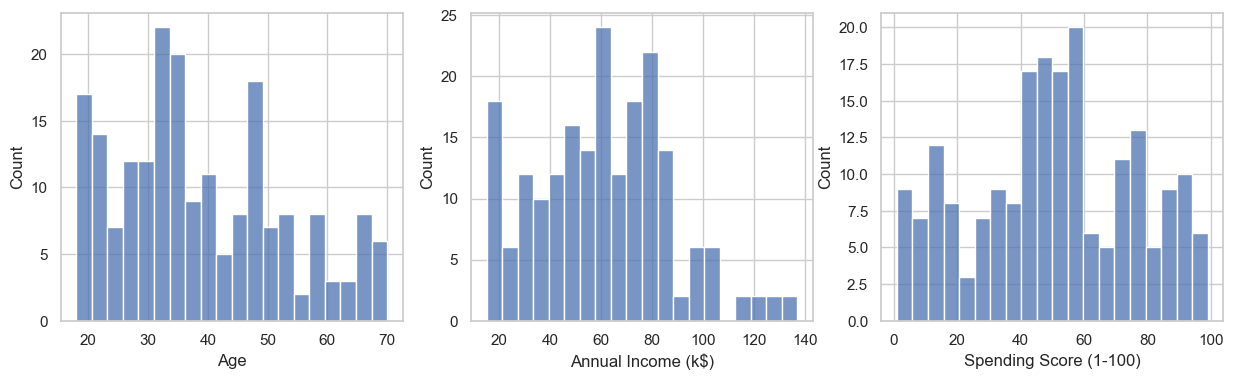

In [23]:
# Histogramas para ver que distribucion tiene
#ajustamos el tamaño de las figuras
plt.figure(figsize=(15,4))
#se hace los 3 plots de las gráficas
plt.subplot(1,3,1)
sns.histplot(df["Age"], bins=20)

plt.subplot(1,3,2)
sns.histplot(df["Annual Income (k$)"], bins=20)

plt.subplot(1,3,3)
sns.histplot(df["Spending Score (1-100)"], bins=20)

plt.show()


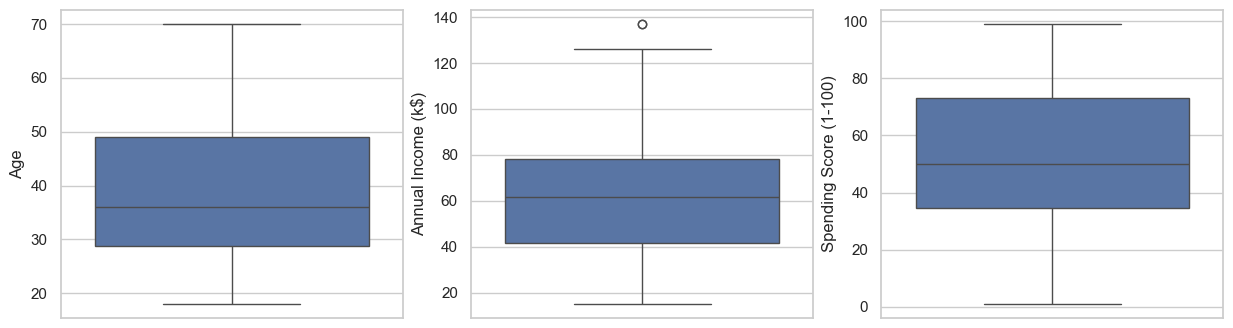

In [24]:

#Grafica de cajas para ver el panorama general
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
sns.boxplot(y=df["Age"])

plt.subplot(1,3,2)
sns.boxplot(y=df["Annual Income (k$)"])

plt.subplot(1,3,3)
sns.boxplot(y=df["Spending Score (1-100)"])

plt.show()


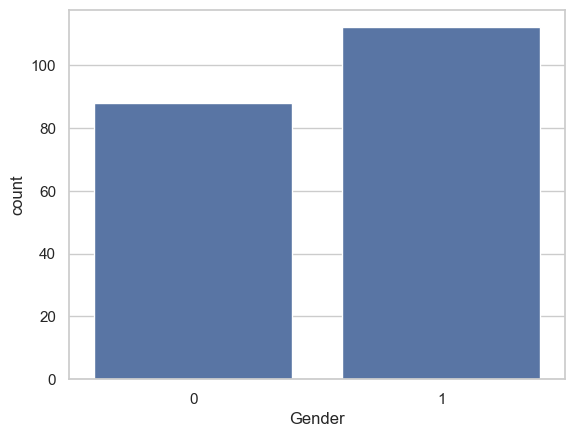

In [25]:
plt.figure()
sns.countplot(x="Gender", data=df)
plt.show()


In [26]:
df_model = df.drop("CustomerID", axis=1)


In [28]:
variables = df_model[["Gender","Age","Annual Income (k$)","Spending Score (1-100)"]]


In [29]:
variables_norm = (variables - variables.min()) / (variables.max() - variables.min())
variables_norm.head()


,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,0.0,0.019231,0.000000,0.387755
1,0.0,0.057692,0.000000,0.816327
2,1.0,0.038462,0.008197,0.051020
3,1.0,0.096154,0.008197,0.775510
4,1.0,0.250000,0.016393,0.397959


In [30]:
variables_norm.describe()


,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,0.560000,0.400962,0.373443,0.502041
std,0.497633,0.268635,0.215285,0.263505
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.206731,0.217213,0.344388
50%,1.000000,0.346154,0.381148,0.500000
75%,1.000000,0.596154,0.516393,0.734694
max,1.000000,1.000000,1.000000,1.000000


In [32]:
inertia = []

for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(variables_norm)
    inertia.append(kmeans.inertia_)


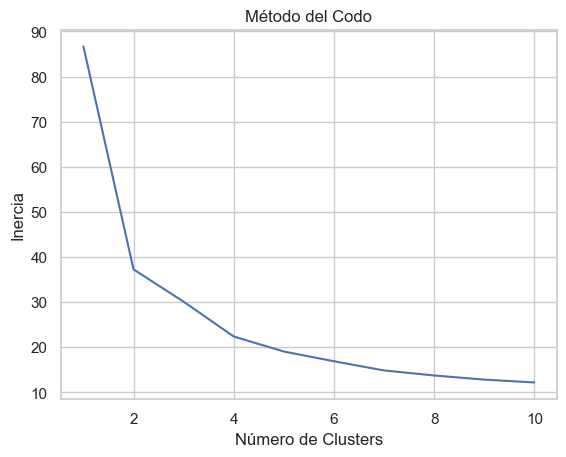

In [33]:
plt.figure()
plt.plot(range(1,11), inertia)
plt.xlabel("Número de Clusters")
plt.ylabel("Inercia")
plt.title("Método del Codo")
plt.show()


In [34]:
kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(variables_norm)

df["Cluster"] = clusters


In [35]:
pca = PCA(n_components=2)
components = pca.fit_transform(variables_norm)

df["PCA1"] = components[:,0]
df["PCA2"] = components[:,1]


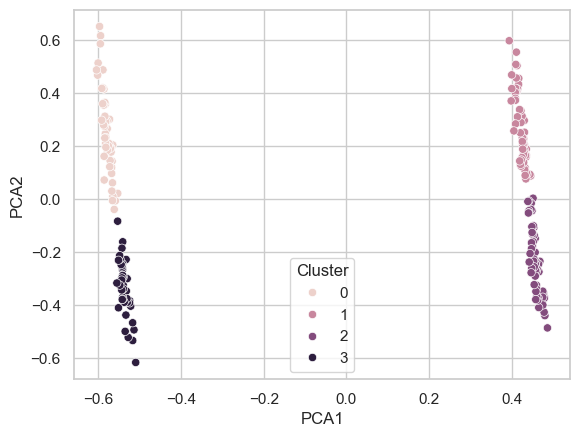

In [36]:
plt.figure()
sns.scatterplot(x="PCA1", y="PCA2", hue="Cluster", data=df)
plt.show()


In [37]:
df.groupby("Cluster").mean()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),PCA1,PCA2
Cluster,,,,,,,
0,104.958333,0.0,49.437500,62.416667,29.208333,-0.579920,0.254101
1,94.818182,1.0,48.109091,58.818182,34.781818,0.422065,0.268381
2,100.210526,1.0,28.438596,59.666667,67.684211,0.458116,-0.235894
3,103.375000,0.0,28.250000,62.000000,71.675000,-0.537250,-0.337797


In [38]:
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(variables_norm)

df["Cluster"] = clusters


In [39]:
pca = PCA(n_components=2)
components = pca.fit_transform(variables_norm)

df["PCA1"] = components[:,0]
df["PCA2"] = components[:,1]


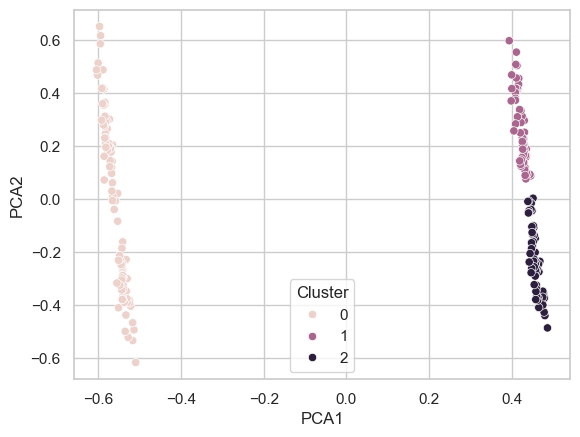

In [40]:
plt.figure()
sns.scatterplot(x="PCA1", y="PCA2", hue="Cluster", data=df)
plt.show()


In [41]:
df.groupby("Cluster").mean()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),PCA1,PCA2
Cluster,,,,,,,
0,104.238636,0.0,39.806818,62.227273,48.511364,-0.560525,-0.014943
1,94.818182,1.0,48.109091,58.818182,34.781818,0.422065,0.268381
2,100.210526,1.0,28.438596,59.666667,67.684211,0.458116,-0.235894
